# Etape 2 - Transformation et préparation des données

## 2-1 Diviser les données en deux ensembles (80 % / 20 %)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


TARGET = 'Mental_Health_Risk'
RANDOM_STATE = 42

df_clean = df_without_student_id.copy()
df_clean['Social_Media_Hours'] = df_clean['Social_Media_Hours'].clip(upper=df_clean['Screen_Time_Hours'])


In [80]:
categorical_features = categorical_columns.drop(TARGET)

ordinal_cols = ['Physical_Activity', 'Diet_Quality']
ordinal_categories = [['Low', 'Moderate', 'High'], ['Poor', 'Average', 'Good']]
nominal_cols = categorical_features.drop(ordinal_cols)

In [81]:
assert (df_clean['Social_Media_Hours'] > df_clean['Screen_Time_Hours']).sum() == 0
print('OK')

OK


In [82]:


X = df_clean.drop(columns=TARGET)
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(1600, 15) (400, 15)


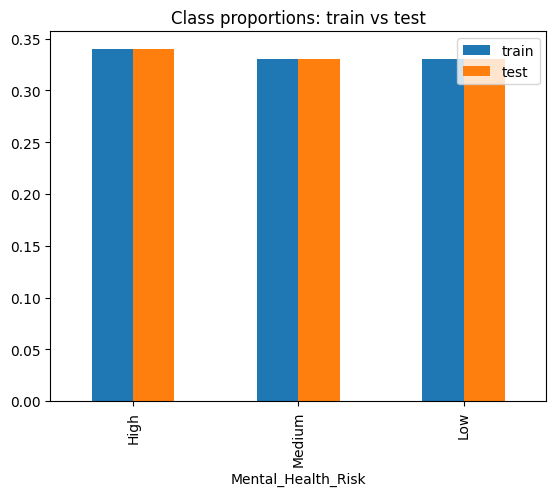

In [83]:
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test': y_test.value_counts(normalize=True)}).plot.bar()
plt.title('Class proportions: train vs test')
plt.show()

## 2-2 Traiter les valeurs manquantes

In [84]:
numeric_imputer = SimpleImputer(strategy='median')
categorical_imputer = SimpleImputer(strategy='most_frequent')

In [85]:
filled = numeric_imputer.fit_transform(X_train[numerical_columns])
assert not np.isnan(filled).any()

print(pd.DataFrame(filled, columns=numerical_columns).isnull().sum())

Age                     0
Year_of_Study           0
Sleep_Hours             0
Study_Hours_Per_Week    0
GPA                     0
Social_Media_Hours      0
Screen_Time_Hours       0
Financial_Stress        0
Family_Support          0
Attendance_Rate         0
dtype: int64


In [86]:
filled_cat = categorical_imputer.fit_transform(X_train[ordinal_cols])
print(pd.DataFrame(filled_cat, columns=ordinal_cols).isnull().sum())

Physical_Activity    0
Diet_Quality         0
dtype: int64


## 2-3 Détecter et traiter les valeurs aberrantes

In [87]:
q1 = X_train[numerical_columns].quantile(0.25)
q3 = X_train[numerical_columns].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

X_train[numerical_columns] = X_train[numerical_columns].clip(lower, upper, axis=1)
X_test[numerical_columns] = X_test[numerical_columns].clip(lower, upper, axis=1)

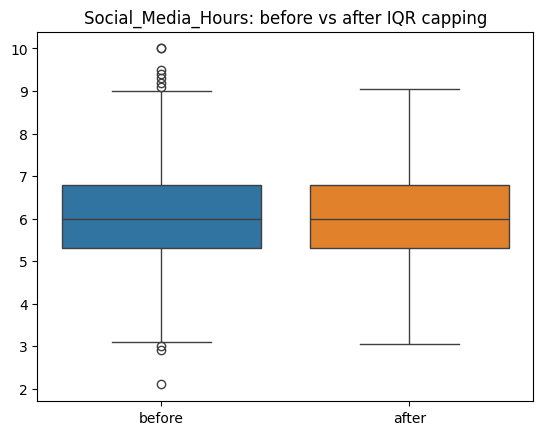

In [88]:
col = 'Social_Media_Hours'
sns.boxplot(data=pd.DataFrame({'before': X.loc[X_train.index, col], 'after': X_train[col]}))
plt.title(f'{col}: before vs after IQR capping')
plt.show()

## 2-4 Encoder les variables catégorielles

In [89]:
ordinal_encoder = OrdinalEncoder(categories=ordinal_categories,
                                 handle_unknown='use_encoded_value', unknown_value=-1)
onehot_encoder = OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False)

In [90]:
enc = ordinal_encoder.fit_transform(X_train[ordinal_cols].dropna())
oh = onehot_encoder.fit_transform(X_train[nominal_cols])

display(pd.DataFrame(enc, columns=ordinal_cols).head())
display(pd.DataFrame(oh, columns=onehot_encoder.get_feature_names_out()).head())

,Physical_Activity,Diet_Quality
0,1.0,1.0
1,2.0,1.0
2,1.0,1.0
3,1.0,1.0
4,2.0,1.0


,Gender_Female,Gender_Male,Gender_Non-binary,Part_Time_Job_Yes,Previous_Mental_Health_History_Yes
0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,1.0,1.0


## 2-6 Normaliser / standardiser

In [91]:
scaler = StandardScaler()

In [92]:
s = pd.DataFrame(scaler.fit_transform(X_train[numerical_columns]), columns=numerical_columns)
print(s)

           Age  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week       GPA  \
0    -0.063471      -0.471636    -1.384634             -0.239251  0.073645   
1     0.876838      -1.232340    -1.652532             -1.334412 -0.967140   
2    -1.003780      -0.471636     0.401357             -0.517387 -1.024961   
3     0.876838      -1.232340     1.383652             -0.082800  0.883144   
4     0.406684       0.289067     0.401357              0.664691 -0.273284   
...        ...            ...          ...                   ...       ...   
1595  0.406684       0.289067    -1.473933             -1.091043  0.073645   
1596  0.876838      -0.471636    -0.402339             -0.274018  0.362751   
1597 -1.944088       1.810475     0.044159              0.299637  0.709680   
1598  0.406684       1.049771    -0.759537              0.751608  0.594037   
1599 -0.533625      -1.232340    -0.938136             -0.360936 -0.793676   

      Social_Media_Hours  Screen_Time_Hours  Financial_Stress  

## 2-7 Regrouper les transformations dans un pipeline

In [93]:
numeric_pipeline = Pipeline([
    ('imputer', numeric_imputer),
    ('scaler', scaler),
])

In [94]:
test = numeric_pipeline.fit_transform(X_train[numerical_columns])
print(test.shape)

(1600, 10)


In [95]:
ordinal_pipeline = Pipeline([
    ('imputer', categorical_imputer),
    ('encoder', ordinal_encoder),
])

In [96]:
test = ordinal_pipeline.fit_transform(X_train[ordinal_cols])
print(test.shape)

(1600, 2)


In [97]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numerical_columns),
    ('ord', ordinal_pipeline, ordinal_cols),
    ('nom', onehot_encoder, nominal_cols),
])

In [98]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

In [120]:
print(X_train_prepared.shape, X_test_prepared.shape)
print(pd.DataFrame(X_train_prepared).isnull().sum().sum())

(1600, 17) (400, 17)
0
